# Modelado del consumo de Frío

Comparamos cuatro regresores para pronosticar el consumo del día siguiente y contrastamos el ganador con persistencia y media móvil de siete días. Ejecutá el notebook con el entorno Python 3.12 del proyecto.

Los modelos se ajustan sobre Train y se comparan en Validation. Esa misma partición se usó en Optuna para elegir los hiperparámetros, por lo que la tabla de Validation documenta la selección. Al final mostramos el resultado del Test interno que ya quedó guardado para el modelo final.

In [1]:
from contextlib import redirect_stdout
from io import StringIO
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display


raiz = Path.cwd()
if not (raiz / "src" / "train_model.py").is_file():
    raiz = raiz.parent
if not (raiz / "src" / "train_model.py").is_file():
    raise FileNotFoundError("Abrí el notebook desde la raíz del TP o desde su carpeta notebooks.")
sys.path.insert(0, str(raiz / "src"))

from evaluate_model import baselines_validacion, calcular_metricas, evaluar_mejor_modelo
from train_model import (
    NOMBRES_MODELOS,
    cargar_datos_preprocesados,
    cargar_mejores_parametros,
    crear_modelo,
    hash_archivo,
    resolver_ruta_csv,
)

## Datos e hiperparámetros

Usamos el CSV del preprocesamiento y las 10 variables seleccionadas en Train. El [notebook de Optuna](optuna_optimization.ipynb) documenta los espacios de búsqueda. Comprobamos que los parámetros guardados correspondan a la huella del dataset que cargamos.

In [2]:
ruta_datos = resolver_ruta_csv()
huella = hash_archivo(ruta_datos)

ruta_optuna = raiz / "results" / "optuna_run_metadata.json"
optuna = json.loads(ruta_optuna.read_text(encoding="utf-8"))
if optuna["dataset_sha256"] != huella:
    raise ValueError("El CSV cambió desde la corrida registrada de Optuna. Verificá qué dataset querés documentar.")

with redirect_stdout(StringIO()):
    parametros = cargar_mejores_parametros(ruta_datos=ruta_datos)
    X_train, y_train, X_val, y_val, X_test, _ = cargar_datos_preprocesados(ruta_datos)

particiones = {"Train": X_train, "Validation": X_val, "Test": X_test}
display(pd.DataFrame.from_dict({
    nombre: {
        "Días": len(x),
        "Variables": x.shape[1],
        "Desde": x.index.min().date(),
        "Hasta": x.index.max().date(),
    }
    for nombre, x in particiones.items()
}, orient="index"))

print(f"Optuna ejecutó {optuna['n_trials_por_modelo']} intentos por modelo con semilla {optuna['semilla']}.")
for nombre in NOMBRES_MODELOS:
    print(f"{nombre} · {json.dumps(parametros[nombre], ensure_ascii=False)}")

,Días,Variables,Desde,Hasta
Train,770,10,2020-07-01,2022-10-27
Validation,165,10,2022-10-28,2023-04-26
Test,165,10,2023-04-27,2023-10-24


Optuna ejecutó 60 intentos por modelo con semilla 42.
XGBoost · {"n_estimators": 350, "max_depth": 1, "learning_rate": 0.018223713463916682, "subsample": 0.6783570800164274, "colsample_bytree": 0.709139509881038, "min_child_weight": 8}
Random Forest · {"n_estimators": 400, "max_depth": 15, "min_samples_split": 11, "min_samples_leaf": 12, "max_features": 0.5817427927757659}
LightGBM · {"n_estimators": 650, "num_leaves": 7, "learning_rate": 0.005011308342072226, "max_depth": 8, "min_child_samples": 53}
Ridge · {"alpha": 13.715751458761106}


## Comparación en Validation

Seleccionamos el modelo con el menor MAE, expresado en kW. También mostramos RMSE y R². Persistencia usa el último consumo observado y la media móvil usa las observaciones disponibles en los siete días previos. La columna «Fechas» indica cuántas observaciones se compararon por método.

In [3]:
modelos, metricas = {}, {}
for nombre in NOMBRES_MODELOS:
    modelo = crear_modelo(nombre, parametros[nombre])
    modelo.fit(X_train, y_train)
    modelos[nombre] = modelo
    metricas[nombre] = calcular_metricas(y_val, modelo.predict(X_val))

ranking = pd.DataFrame.from_dict(metricas, orient="index").sort_values("MAE")
ganador = ranking.index[0]
segundo = ranking.index[1]
ventaja = ranking.loc[segundo, "MAE"] - ranking.loc[ganador, "MAE"]
comparacion_val = pd.concat([
    ranking.assign(Fechas=len(y_val)),
    baselines_validacion(y_train, y_val),
])
comparacion_val.index.name = "Método"
display(comparacion_val.round({"MAE": 2, "RMSE": 2, "R2": 3}))
print(f"{ganador} obtuvo el menor MAE entre los cuatro modelos, {ventaja:.2f} kW por debajo de {segundo}.")

,MAE,RMSE,R2,Fechas
Método,,,,
Ridge,2264.51,2891.12,0.428,165
Random Forest,2366.30,3001.97,0.383,165
XGBoost,2371.73,2982.31,0.391,165
LightGBM,2416.16,3064.65,0.357,165
Persistencia,2701.46,3325.71,0.243,165
Media móvil 7 días,2483.69,3229.29,0.286,165


Ridge obtuvo el menor MAE entre los cuatro modelos, 101.79 kW por debajo de Random Forest.


## Diagnóstico del ganador

El gráfico de predicción contra valor real muestra qué tan cerca queda el modelo de la diagonal. En el gráfico de residuos, un valor positivo significa que el modelo estimó de menos. La importancia por permutación mide el aumento del MAE al desordenar una variable en Validation. Con variables correlacionadas, la señal puede repartirse entre varias.


Mejor modelo por MAE de validación: Ridge
MAE     2264.514818
RMSE    2891.122830
R2         0.427686
Name: Ridge, dtype: float64


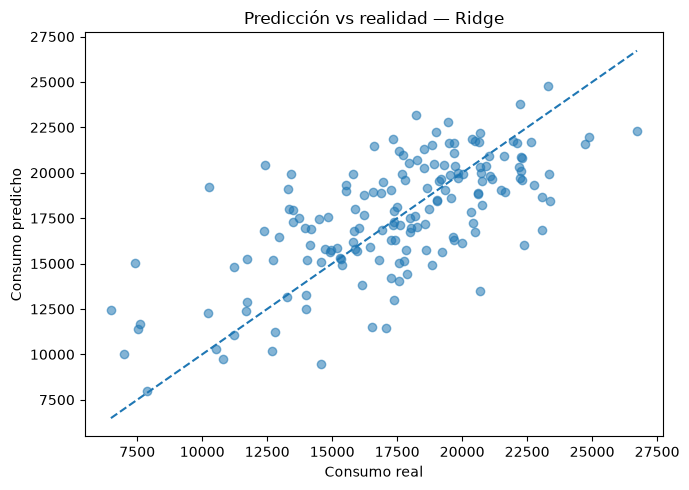

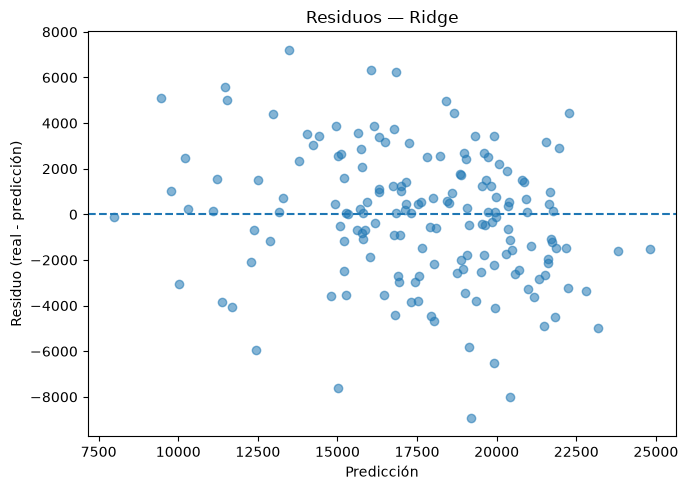


Importancia de variables (variación estimada del MAE):
                                       Variable  Importancia
                     Frio (Kw) (Consolidado EE)   515.618477
         Frio (Kw) (Consolidado EE)_MediaMov_7d   109.081149
               Frio (Kw) (Consolidado EE)_Lag_1   106.558472
            Agua Planta (Hl) (Consolidado Agua)    15.380920
     ET Bodega/Hl (Consolidado KPI)_MediaMov_7d     0.923792
               Frio (Kw) (Consolidado EE)_Lag_7    -1.328972
            KW Trafo 11 (Totalizadores Energia)    -2.668286
KW Trafo 11 (Totalizadores Energia)_MediaMov_7d    -3.811520
       KW Cond 5. 6 y 9 (Totalizadores Energia)    -9.737913
  FC Centec II (Totalizadores Agua)_MediaMov_7d   -10.510294
El residuo medio en Validation fue de -197.98 kW.


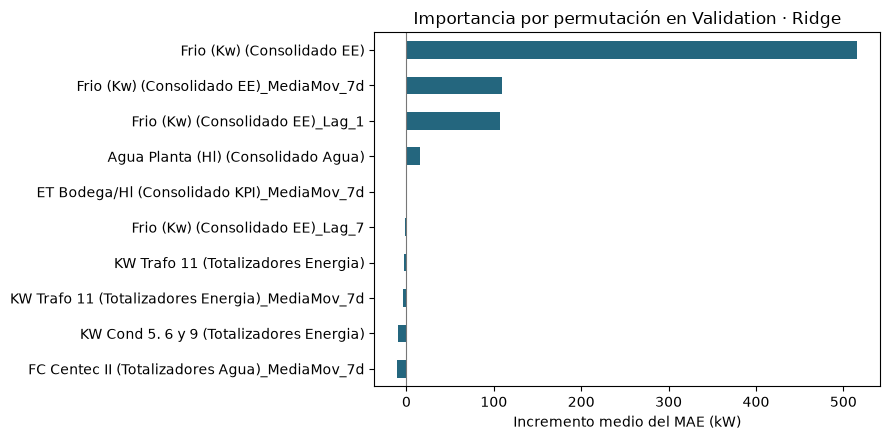

In [4]:
importancias = evaluar_mejor_modelo(modelos, ranking, X_val, y_val)
predicciones = modelos[ganador].predict(X_val)
residuos = y_val - predicciones
print(f"El residuo medio en Validation fue de {residuos.mean():.2f} kW.")

ax = importancias.sort_values("Importancia").plot.barh(
    x="Variable",
    y="Importancia",
    legend=False,
    figsize=(9, 4.5),
    color="#24667e",
)
ax.set_title(f"Importancia por permutación en Validation · {ganador}")
ax.set_xlabel("Incremento medio del MAE (kW)")
ax.set_ylabel("")
ax.axvline(0, color="#777777", linewidth=0.8)
plt.tight_layout()
plt.show()

## Modelo publicado y Test interno

El modelo elegido se reentrenó con Train + Validation y quedó registrado con versión semántica. Esta sección lee el reporte del Test interno guardado en el repositorio. La tabla corresponde al modelo ya serializado y a las fechas comunes con los dos baselines.

In [5]:
registro = json.loads((raiz / "models" / "model_registry.json").read_text(encoding="utf-8"))
version = registro["latest"]
ficha = registro["models"][version]
if ficha["dataset_sha256"] != huella:
    raise ValueError("El CSV no corresponde al modelo publicado que figura en el registro.")

ruta_test = raiz / "results" / f"evaluacion_test_{version}.json"
reporte = json.loads(ruta_test.read_text(encoding="utf-8"))
if (reporte["version"], reporte["algoritmo"]) != (version, ficha["algoritmo"]):
    raise ValueError("El reporte de Test no corresponde al modelo del registro.")

tabla_test = pd.DataFrame.from_dict(reporte["comparacion_fechas_comunes"], orient="index").sort_values("MAE")
tabla_test.index.name = "Método"
mae_modelo = tabla_test.loc[ficha["algoritmo"], "MAE"]
baselines = tabla_test.loc[["Persistencia", "Media móvil 7 días"], "MAE"]
mejor_baseline = baselines.idxmin()
mejora = 100 * (baselines.min() - mae_modelo) / baselines.min()

print(f"Modelo registrado · {ficha['algoritmo']} {version}")
print(f"Artefacto · {ficha['path']}")
print(f"Fechas comparables · {reporte['n_fechas_comunes']} de {reporte['n_test']}")
display(tabla_test.round({"MAE": 2, "RMSE": 2, "R2": 3}))
print(f"El MAE de Test del modelo fue de {mae_modelo:.2f} kW, un {mejora:.1f} % menor que el de {mejor_baseline}.")

Modelo registrado · Ridge v1.0.0
Artefacto · models/modelo_v1.0.0.pkl
Fechas comparables · 165 de 165


,MAE,RMSE,R2,Fechas
Método,,,,
Ridge,2773.16,3651.26,0.591,165
Media móvil 7 días,3032.90,3889.23,0.536,165
Persistencia,3368.59,4410.20,0.403,165


El MAE de Test del modelo fue de 2773.16 kW, un 8.6 % menor que el de Media móvil 7 días.
